In [14]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# Generate reproducible nonlinear data
np.random.seed(42)

X = np.linspace(0, 10, 40).reshape(-1, 1)

y = 2 + 0.5 * X[:, 0] ** 2 + np.random.normal(0, 5, 40)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

degrees = [1, 2, 3, 4, 5, 10]

for degree in degrees:
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X_train, y_train)

    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_prediction)
    test_mse = mean_squared_error(y_test, test_prediction)

    print(f"polynomial degree: {degree}")
    print(f"  Training MSE: {train_mse:.2f}")
    print(f"  Testing MSE: {test_mse:.2f}")
    print()


polynomial degree: 1
  Training MSE: 42.90
  Testing MSE: 42.99

polynomial degree: 2
  Training MSE: 20.44
  Testing MSE: 19.79

polynomial degree: 3
  Training MSE: 18.46
  Testing MSE: 22.45

polynomial degree: 4
  Training MSE: 17.75
  Testing MSE: 22.36

polynomial degree: 5
  Training MSE: 17.43
  Testing MSE: 19.87

polynomial degree: 10
  Training MSE: 18.26
  Testing MSE: 38.42



In [15]:
X = np.linspace(0, 500, 1000).reshape(-1, 1)

y = 2 + 0.5 * X[:, 0] ** 2 + np.random.normal(0, 10, 1000)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

degrees = [1, 2, 3, 4, 5, 10]

for degree in degrees:
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X_train, y_train)

    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_prediction)
    test_mse = mean_squared_error(y_test, test_prediction)

    print(f"polynomial degree: {degree}")
    print(f"  Training MSE: {train_mse:.2f}")
    print(f"  Testing MSE: {test_mse:.2f}")
    print()


polynomial degree: 1
  Training MSE: 87457411.04
  Testing MSE: 86134251.33

polynomial degree: 2
  Training MSE: 95.18
  Testing MSE: 96.72

polynomial degree: 3
  Training MSE: 95.26
  Testing MSE: 96.26

polynomial degree: 4
  Training MSE: 3195456.27
  Testing MSE: 3018457.20

polynomial degree: 5
  Training MSE: 16180072.23
  Testing MSE: 15239576.43

polynomial degree: 10
  Training MSE: 177803167.72
  Testing MSE: 186244585.54



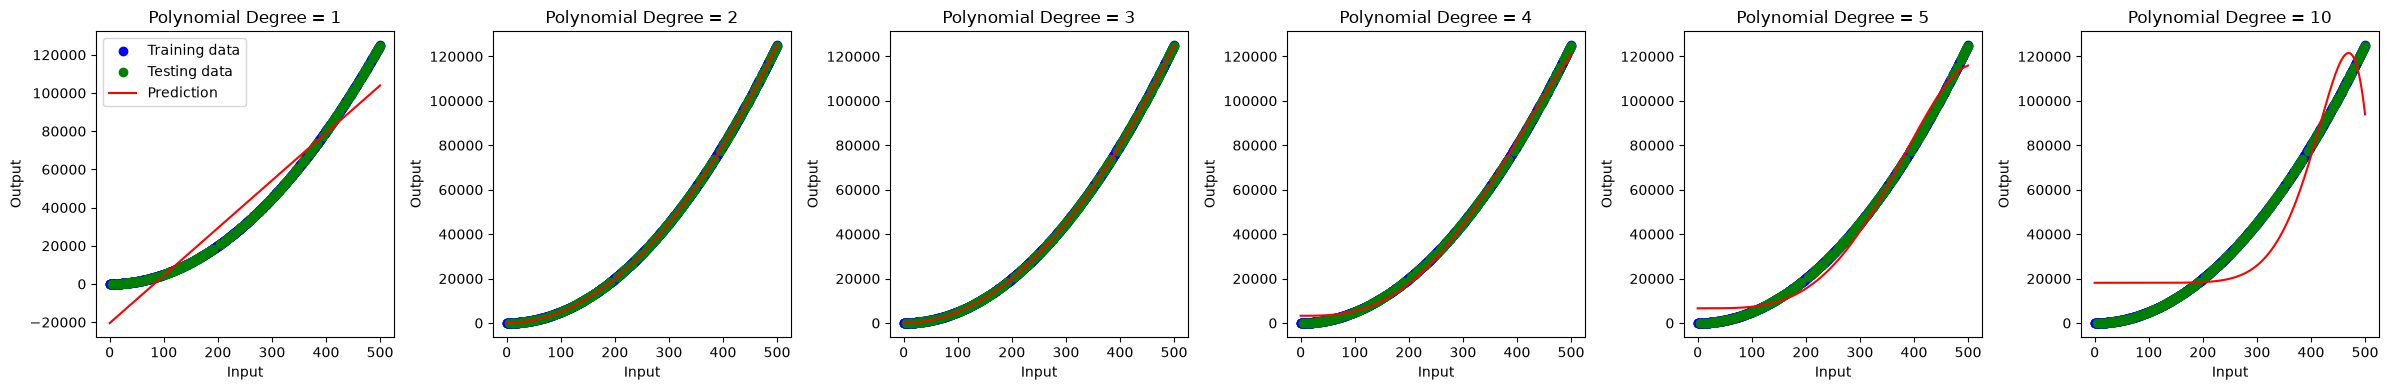

In [18]:
x_plot = np.linspace(X_train.min(), X_train.max(), 200).reshape(-1, 1)
n_plots = len(degrees)
plt.figure(figsize=(4 * n_plots, 4))

for index, degree in enumerate(degrees):
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    y_plot = model.predict(x_plot)

    plt.subplot(1, n_plots, index + 1)

    plt.scatter(X_train, y_train, color="blue", label="Training data")
    plt.scatter(X_test, y_test, color="green", label="Testing data")
    plt.plot(x_plot, y_plot, color="red", label="Prediction")

    plt.title(f"Polynomial Degree = {degree}")
    plt.xlabel("Input")
    plt.ylabel("Output")
    if index == 0:
        plt.legend()

plt.tight_layout()
plt.show()

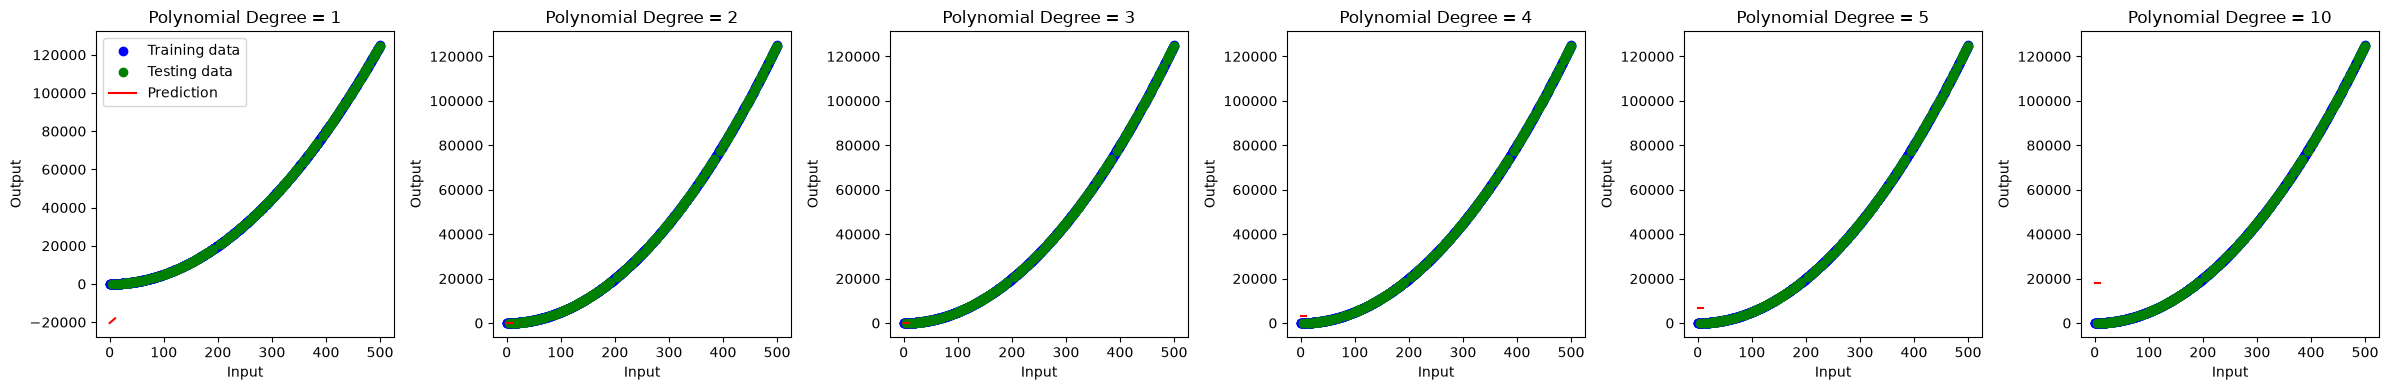

In [17]:
x_plot = np.linspace(0, 10, 200).reshape(-1, 1)
n_plots = len(degrees)
plt.figure(figsize=(4 * n_plots, 4))

for index, degree in enumerate(degrees):
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    y_plot = model.predict(x_plot)

    plt.subplot(1, n_plots, index + 1)

    plt.scatter(X_train, y_train, color="blue", label="Training data")
    plt.scatter(X_test, y_test, color="green", label="Testing data")
    plt.plot(x_plot, y_plot, color="red", label="Prediction")

    plt.title(f"Polynomial Degree = {degree}")
    plt.xlabel("Input")
    plt.ylabel("Output")
    if index == 0:
        plt.legend()

plt.tight_layout()
plt.show()

In [23]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
import numpy as np

for degree in range(1, 11):
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )
    
    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="neg_mean_squared_error"
    )

    mean_mse = -scores.mean()
    print(f"degree: {degree}, cv mse = {mean_mse:.2f}")

degree: 1, cv mse = 326080600.65
degree: 2, cv mse = 96.09
degree: 3, cv mse = 96.08
degree: 4, cv mse = 59995710.37
degree: 5, cv mse = 534470651.31
degree: 6, cv mse = 2335212598.97
degree: 7, cv mse = 7460690792.85
degree: 8, cv mse = 19971436583.65
degree: 9, cv mse = 47778028944.89
degree: 10, cv mse = 105807494422.33
